#ML LAB 7
#Shreya Sharma

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB

In [10]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
                             classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay
                             )
pd.set_option('display.max_columns',None)

In [11]:
df = pd.read_csv("/content/glass - glass.csv")

In [12]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [13]:
df.tail()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
209,1.51623,14.14,0.0,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.0,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.0,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.0,1.94,73.61,0.00,8.48,1.57,0.0,7
213,1.51711,14.23,0.0,2.08,73.36,0.00,8.62,1.67,0.0,7


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [15]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [16]:
df.duplicated().sum()

np.int64(1)

In [17]:
df["RI"].unique()

array([1.52101, 1.51761, 1.51618, 1.51766, 1.51742, 1.51596, 1.51743,
       1.51756, 1.51918, 1.51755, 1.51571, 1.51763, 1.51589, 1.51748,
       1.51784, 1.52196, 1.51911, 1.51735, 1.5175 , 1.51966, 1.51736,
       1.51751, 1.5172 , 1.51764, 1.51793, 1.51721, 1.51768, 1.51747,
       1.51775, 1.51753, 1.51783, 1.51567, 1.51909, 1.51797, 1.52213,
       1.51779, 1.5221 , 1.51786, 1.519  , 1.51869, 1.52667, 1.52223,
       1.51898, 1.5232 , 1.51926, 1.51808, 1.51837, 1.51778, 1.51769,
       1.51215, 1.51824, 1.51754, 1.51905, 1.51977, 1.52172, 1.52227,
       1.52099, 1.52152, 1.523  , 1.51574, 1.51848, 1.51593, 1.51631,
       1.5159 , 1.51645, 1.51627, 1.51613, 1.51592, 1.51646, 1.51594,
       1.51409, 1.51625, 1.51569, 1.5164 , 1.51841, 1.51605, 1.51588,
       1.51629, 1.5186 , 1.51689, 1.51811, 1.51655, 1.5173 , 1.5182 ,
       1.52725, 1.5241 , 1.52475, 1.53125, 1.53393, 1.52222, 1.51818,
       1.52664, 1.52739, 1.52777, 1.51892, 1.51847, 1.51846, 1.51829,
       1.51708, 1.51

In [18]:
df.isnull().sum()

,0
RI,0
Na,0
Mg,0
Al,0
Si,0
K,0
Ca,0
Ba,0
Fe,0
Type,0


In [19]:
df.drop_duplicates()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1
...,...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7


#BAR PLOT

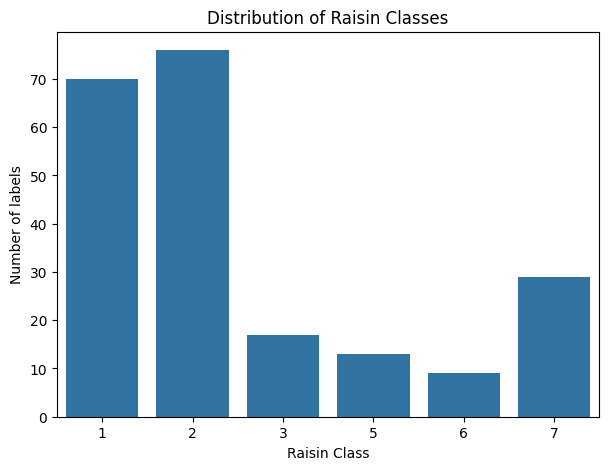

In [20]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="Type")
plt.title("Distribution of Raisin Classes")
plt.xlabel("Raisin Class")
plt.ylabel("Number of labels")
plt.show()

#Pie Chart

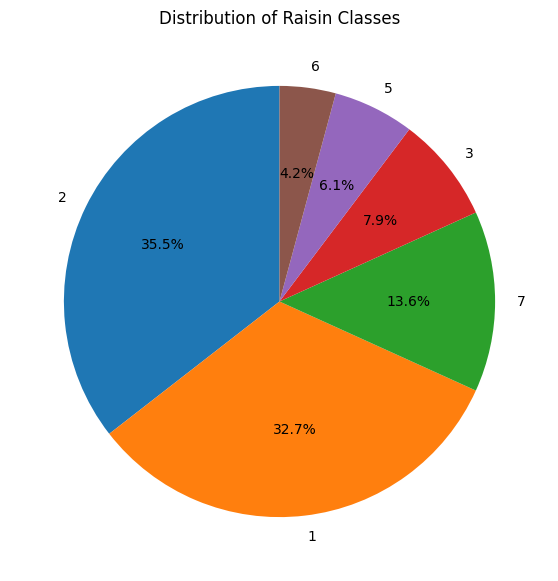

In [21]:
class_counts = df["Type"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=90)
plt.title("Distribution of Raisin Classes")
plt.show()

#Histograms

In [22]:
numerical_features=["RI","Na","Mg","Al","Si","K","Ca","Ba","Fe"]


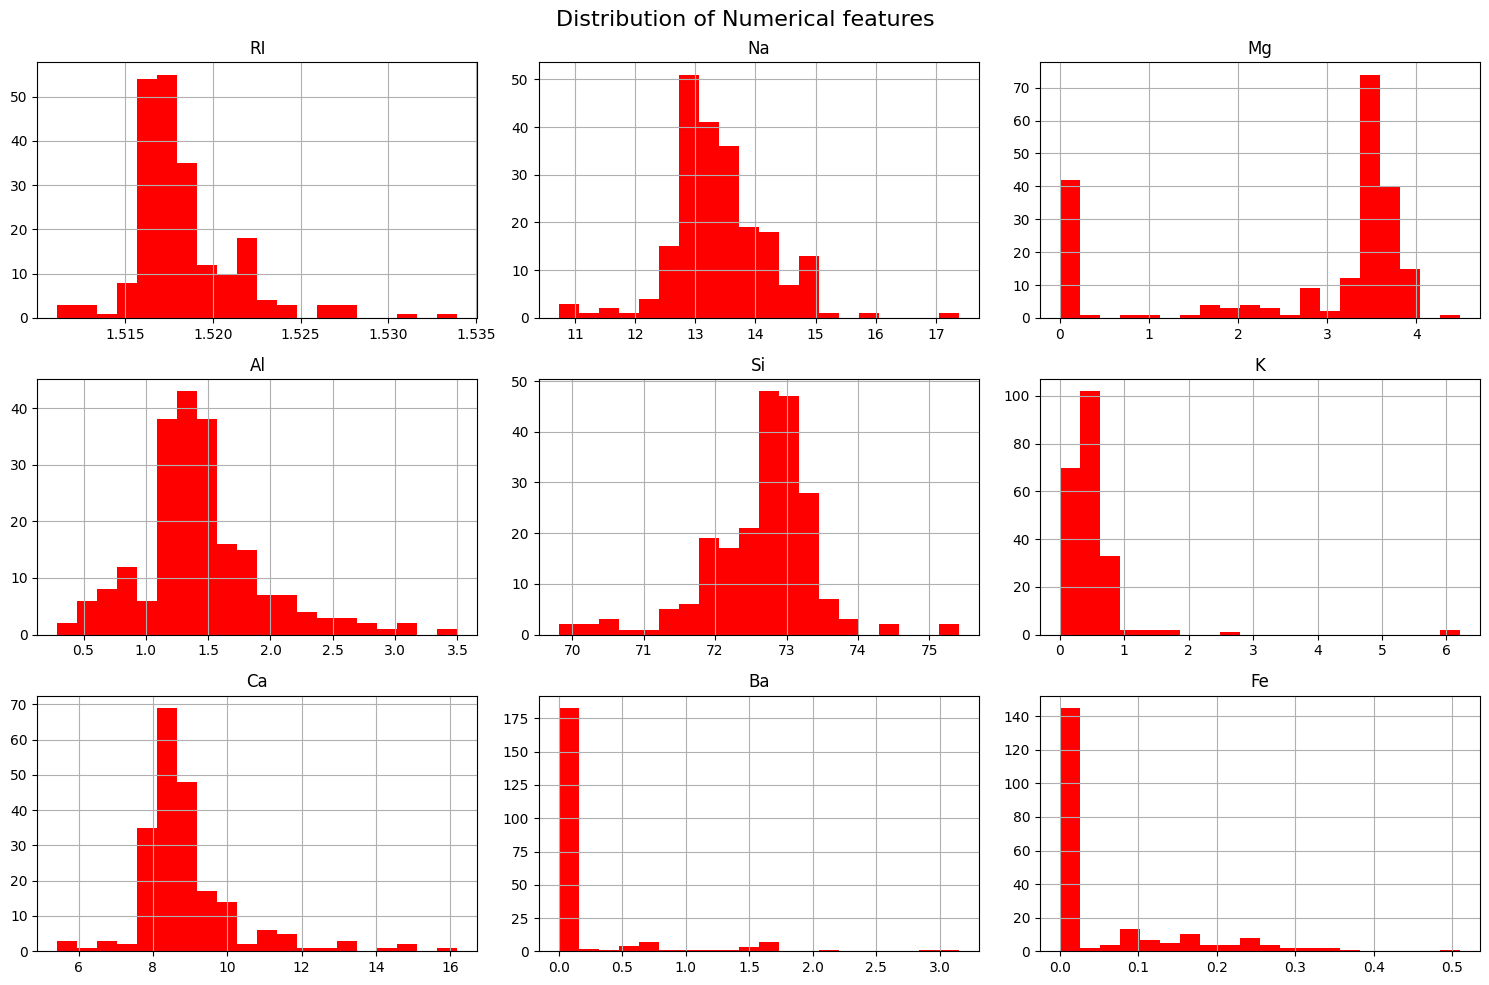

In [23]:
df[numerical_features].hist(figsize=(15,10),bins=20,color='red')
plt.suptitle("Distribution of Numerical features",fontsize=16,)
plt.tight_layout()
plt.show()

#Box Plot

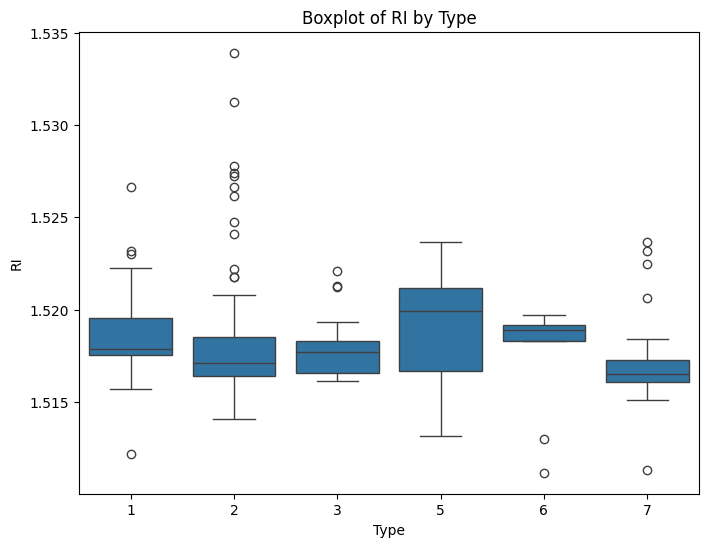

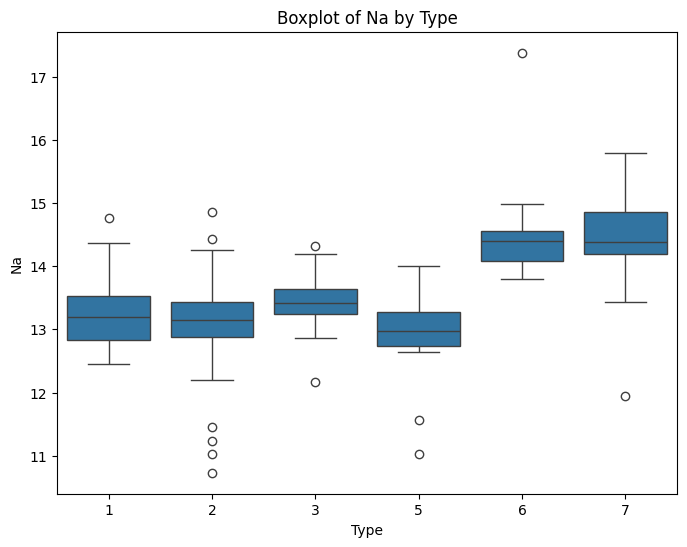

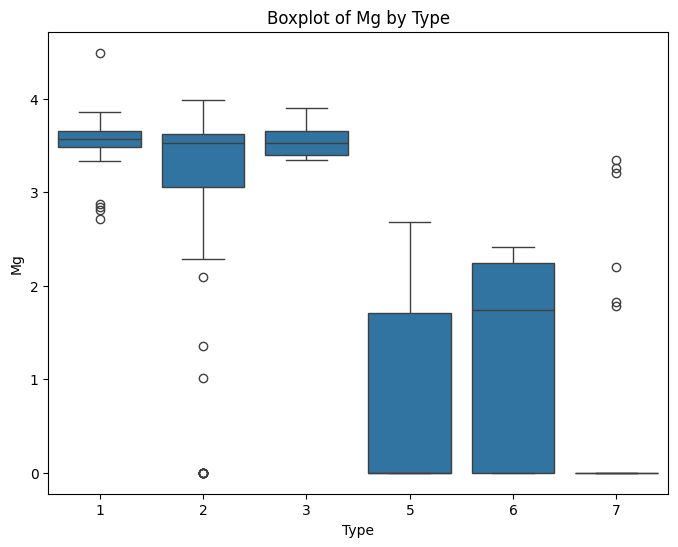

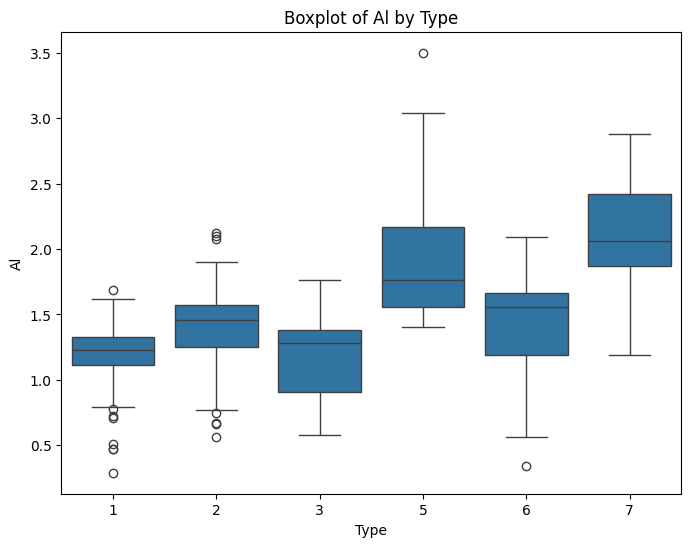

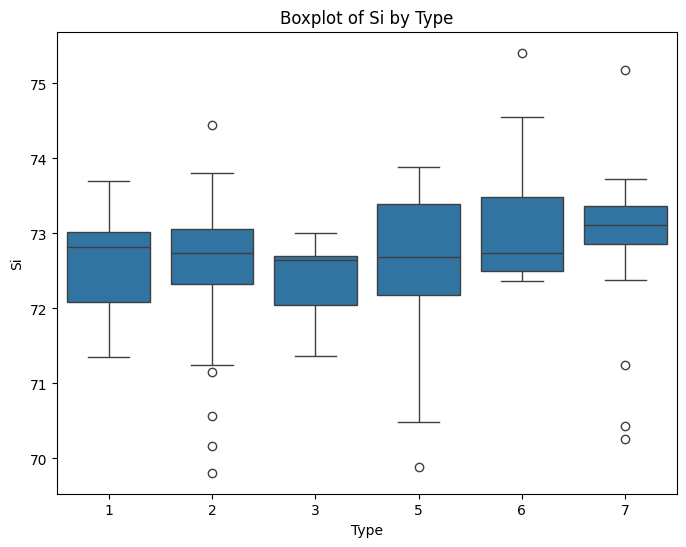

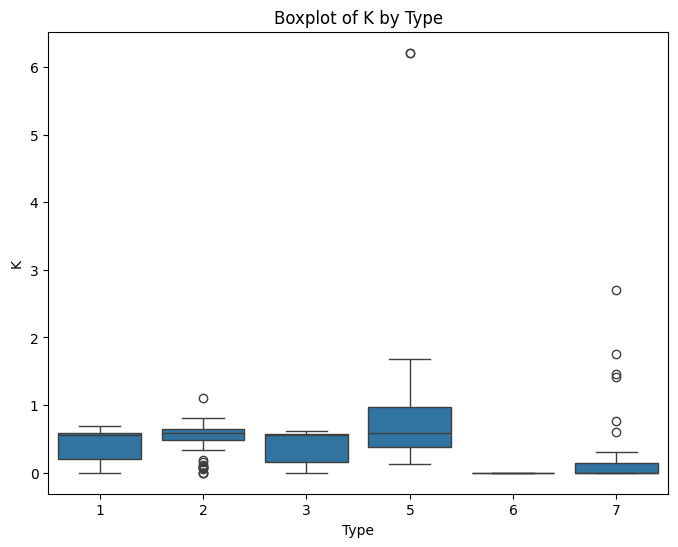

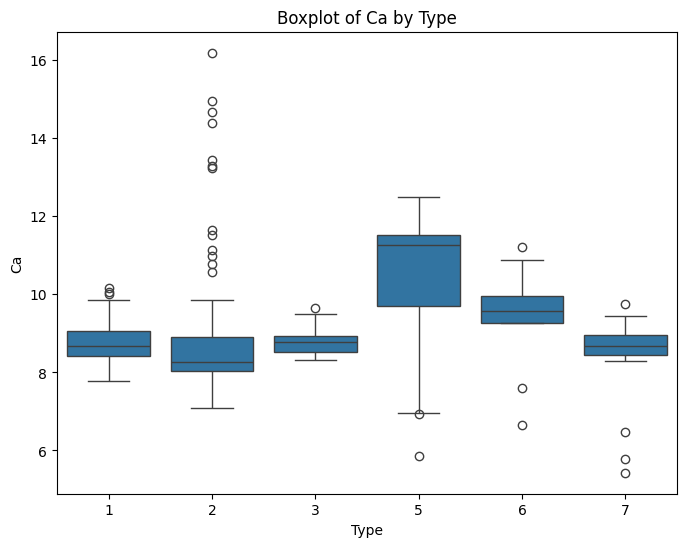

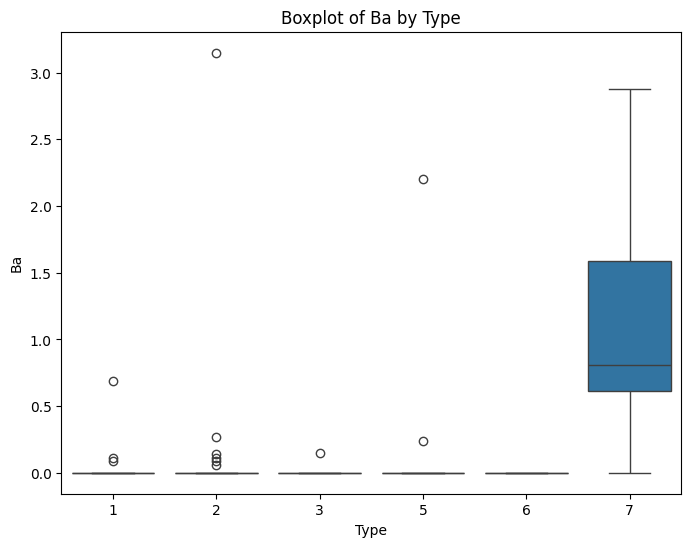

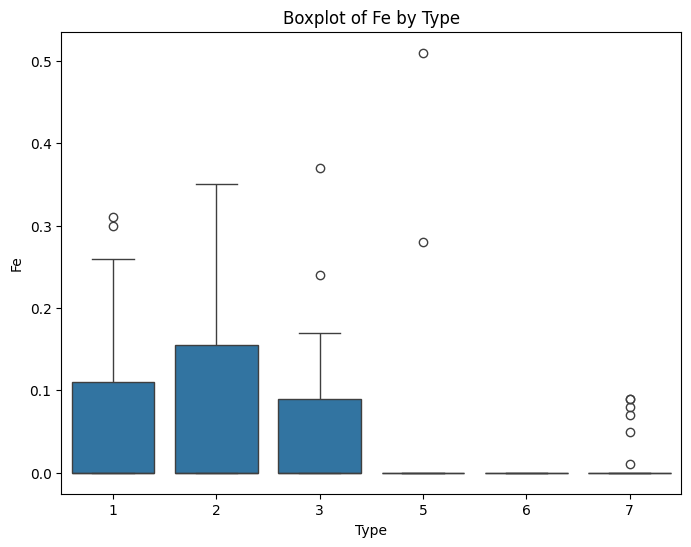

In [24]:
for column in numerical_features:
    plt.figure(figsize=(8, 6))
    sns.boxplot(data=df, x="Type", y=column)
    plt.title(f'Boxplot of {column} by Type')
    plt.xlabel('Type')
    plt.ylabel(column)
    plt.show()


#Histograms with kde Function

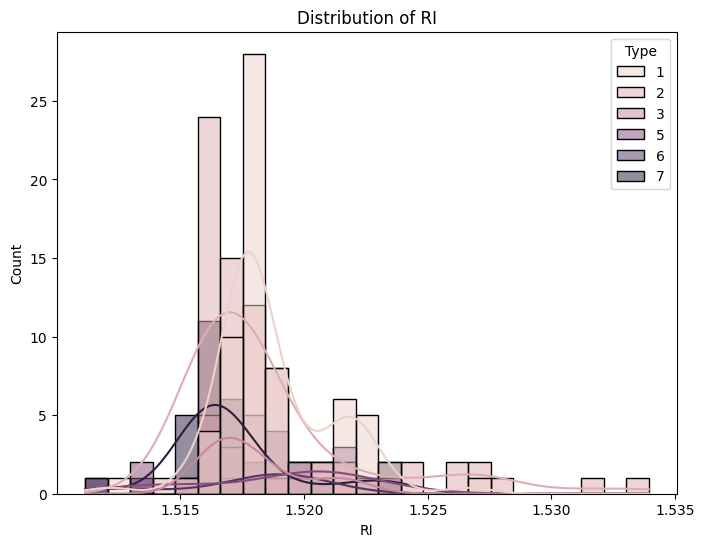

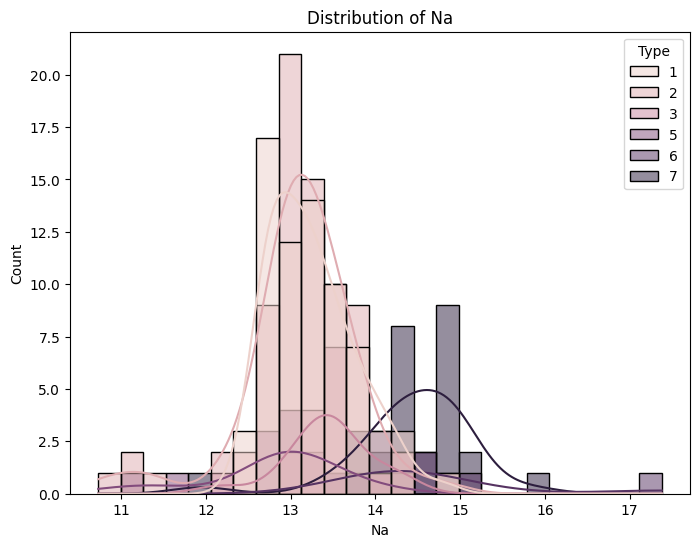

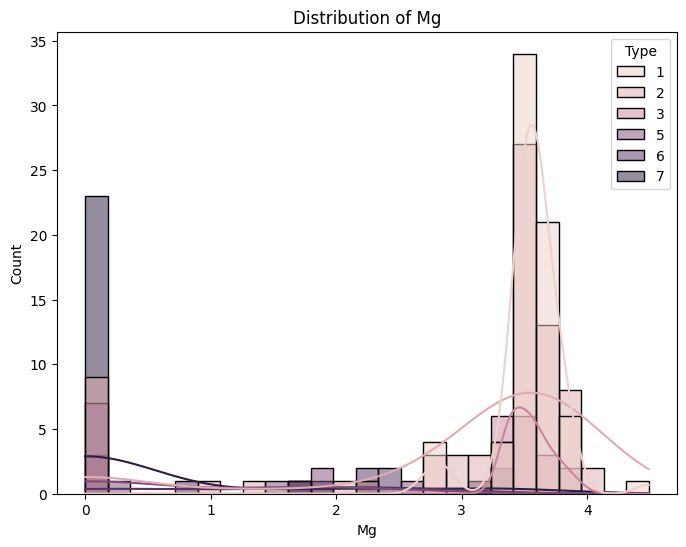

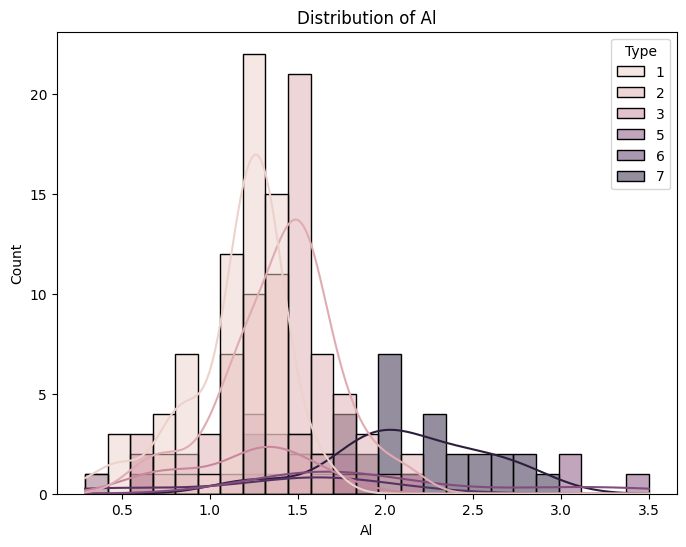

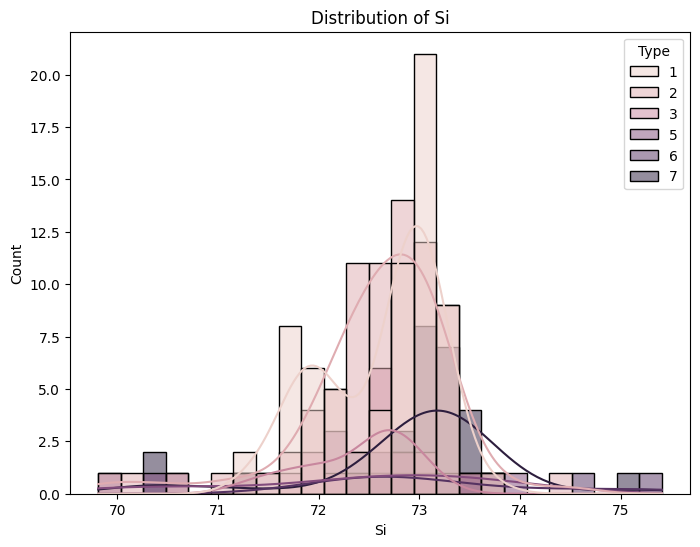

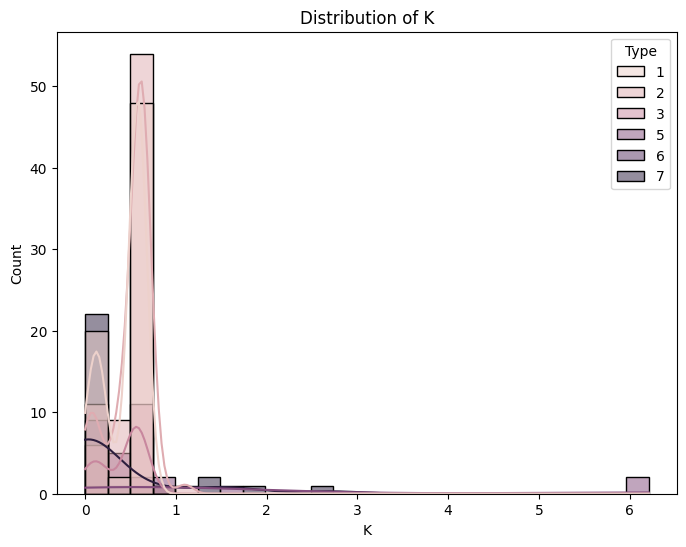

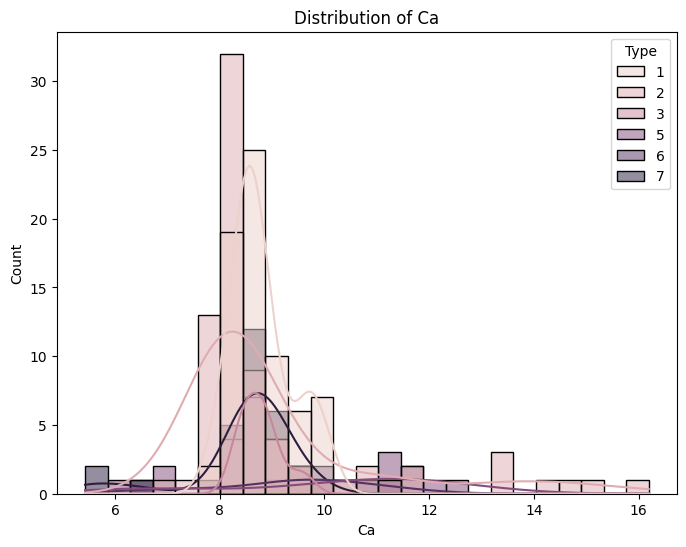

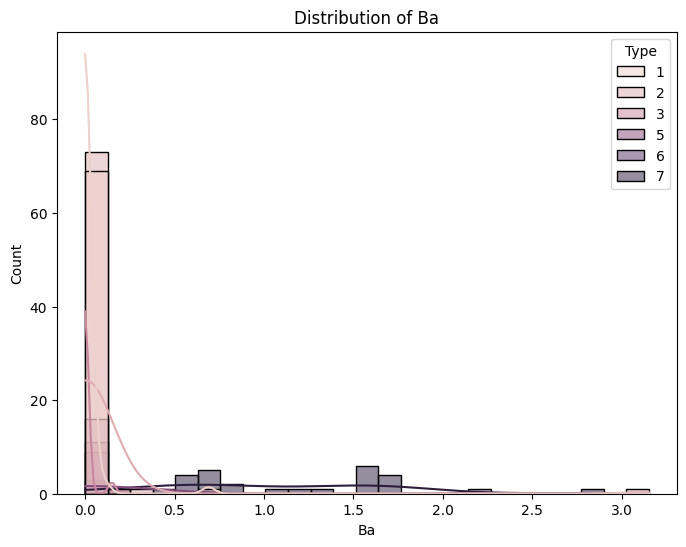

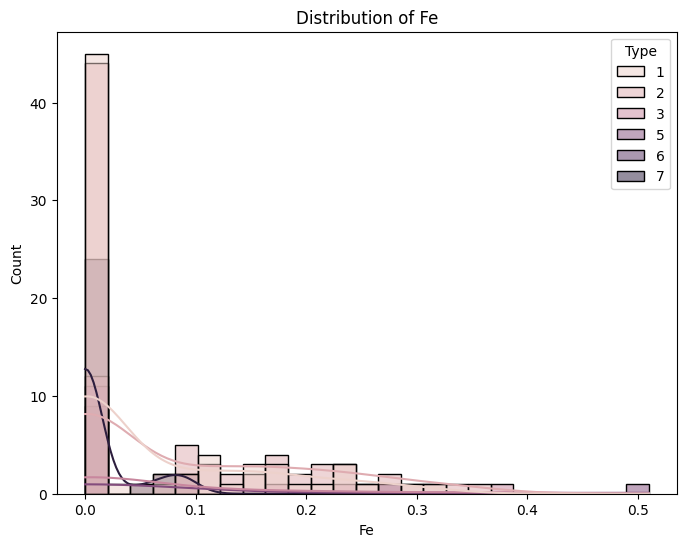

In [25]:
for column in numerical_features:
    plt.figure(figsize=(8, 6))
    sns.histplot(data=df, x=column,hue = "Type", kde=True,bins = 25)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.show()

#Correlation Matrix

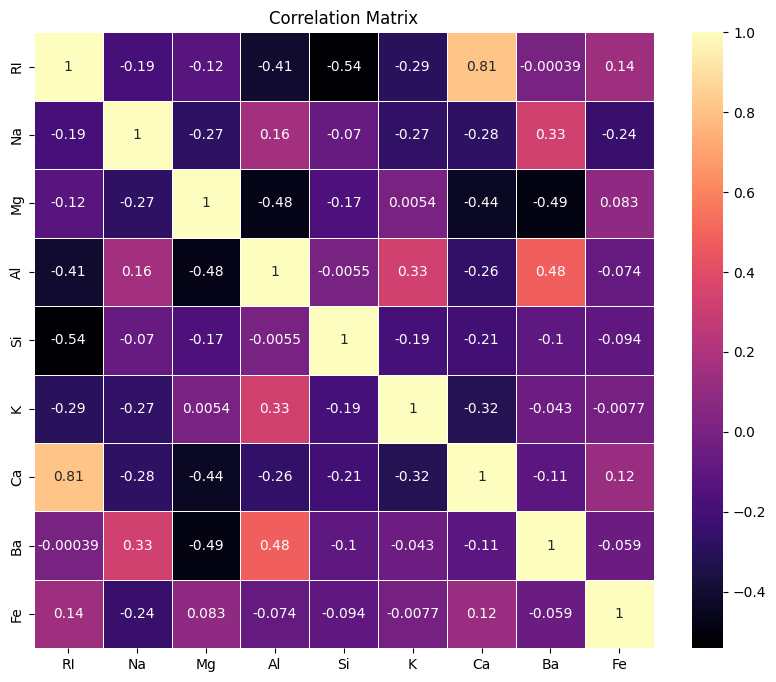

In [26]:
correlation_matrix = df[numerical_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='magma', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

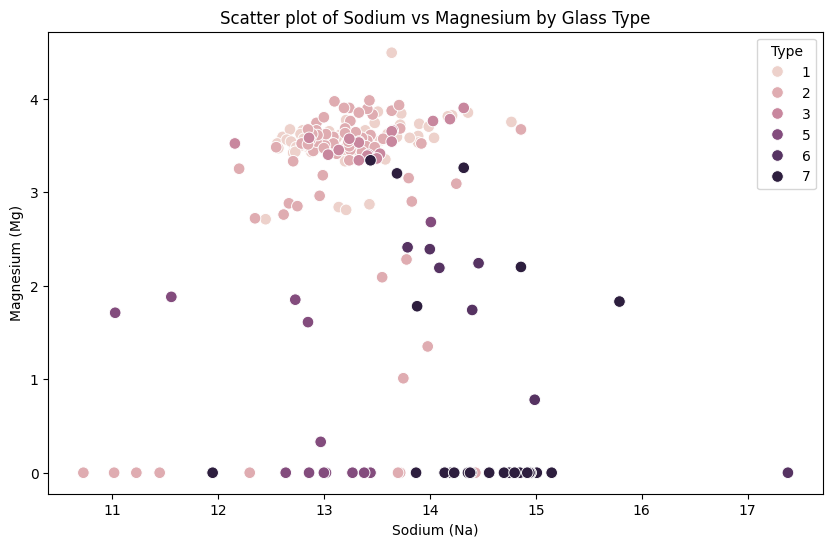

In [27]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x="Na",y="Mg",hue = "Type",s=70)
plt.title('Scatter plot of Sodium vs Magnesium by Glass Type')
plt.xlabel('Sodium (Na)')
plt.ylabel('Magnesium (Mg)')
plt.show()

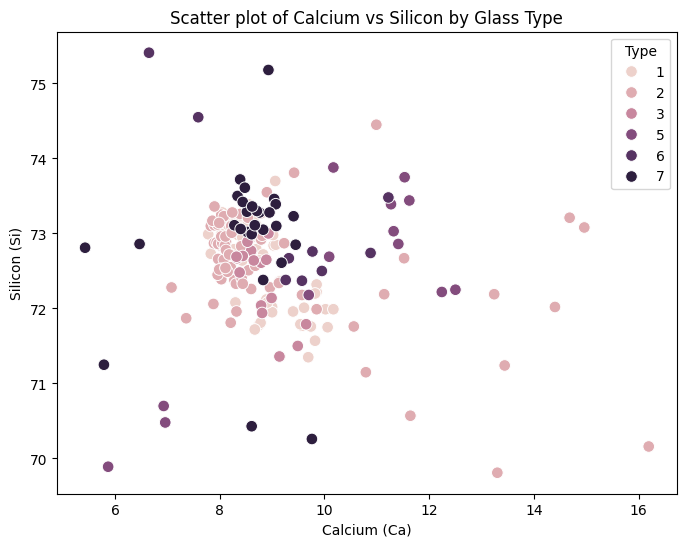

In [28]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df,x="Ca",y="Si",hue = "Type",s=70)
plt.title('Scatter plot of Calcium vs Silicon by Glass Type')
plt.xlabel('Calcium (Ca)')
plt.ylabel('Silicon (Si)')
plt.show()

In [29]:
#data pre_processing
label_encoder = LabelEncoder()
df["Type"] = label_encoder.fit_transform(df["Type"])
print(df[["Type"]].head(5))

   Type
0     0
1     0
2     0
3     0
4     0


In [30]:
print("Type Mapping")
for index, label in enumerate(label_encoder.classes_):
    print(f"{index} : {label}")

Type Mapping
0 : 1
1 : 2
2 : 3
3 : 5
4 : 6
5 : 7


In [31]:
X = df[numerical_features]
y = df["Type"]
print("X shape:",X.shape)
print("y shape:",y.shape)

X shape: (214, 9)
y shape: (214,)


In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (171, 9)
X_test shape: (43, 9)
y_train shape: (171,)
y_test shape: (43,)


#Model Training and Prediction

In [33]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)

GaussianNB()

In [34]:
y_pred = gnb.predict(X_test)
display(pd.DataFrame({'Actual': y_test, 'Predicted': y_pred}).head())

,Actual,Predicted
9,0,0
197,5,5
66,0,0
191,5,5
117,1,0


In [35]:
comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
display(comparison_df.head())

,Actual,Predicted
9,0,0
197,5,5
66,0,0
191,5,5
117,1,0


In [36]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')
print("---Model Performace")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

---Model Performace
Accuracy: 0.5581
Precision: 0.5544
Recall: 0.5581
F1-Score: 0.5317


In [37]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.41      0.64      0.50        11
           1       0.43      0.21      0.29        14
           2       0.40      0.67      0.50         3
           3       0.50      0.25      0.33         4
           4       1.00      1.00      1.00         3
           5       0.89      1.00      0.94         8

    accuracy                           0.56        43
   macro avg       0.60      0.63      0.59        43
weighted avg       0.55      0.56      0.53        43



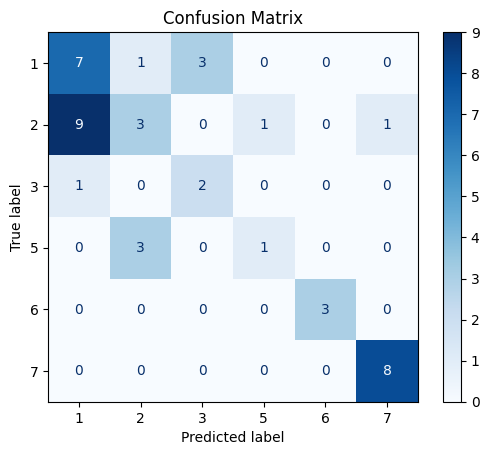

In [38]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

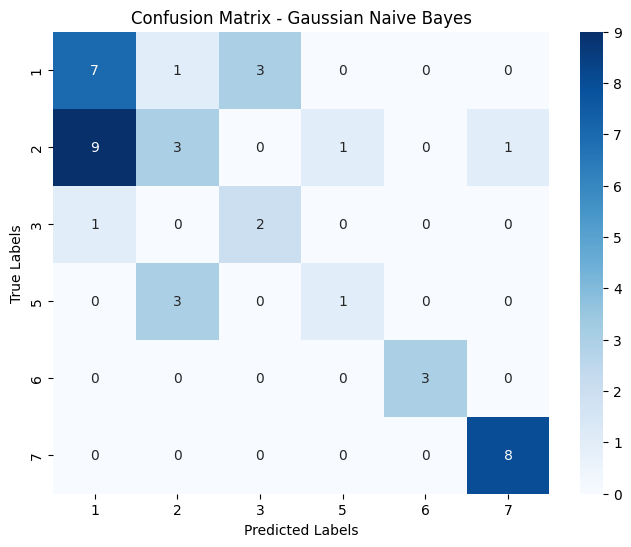

In [39]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix - Gaussian Naive Bayes')
plt.show()

In [40]:
from sklearn.metrics import accuracy_score
y_train_pred = gnb.predict(X_train)
accuracy_train = accuracy_score(y_train, y_train_pred)
accuracy_test = accuracy_score(y_test, y_pred)

print("Training Accuracy:", accuracy_train)
print("Testing Accuracy:", accuracy_test)


Training Accuracy: 0.5614035087719298
Testing Accuracy: 0.5581395348837209


#Main_Hyperparameters

In [41]:
GaussianNB(var_smoothing=1e-09)

GaussianNB()

In [42]:
print(gnb.get_params())

{'priors': None, 'var_smoothing': 1e-09}


In [43]:
smoothing_values = [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]
results = []
for value in smoothing_values:
  model=GaussianNB(var_smoothing=value)
  model.fit(X_train, y_train)
  prediction = model.predict(X_test)
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred, average='weighted')
  recall = recall_score(y_test, y_pred, average='weighted')
  f1 = f1_score(y_test, y_pred, average='weighted')
  results.append((value, accuracy, precision, recall, f1))




In [44]:
new_sample_data = {}

print("Please enter values for the following features:")
new_sample_data['RI'] = float(input("Enter Refractive Index (RI): "))
new_sample_data['Na'] = float(input("Enter Sodium (Na): "))
new_sample_data['Mg'] = float(input("Enter Magnesium (Mg): "))
new_sample_data['Al'] = float(input("Enter Aluminum (Al): "))
new_sample_data['Si'] = float(input("Enter Silicon (Si): "))
new_sample_data['K'] = float(input("Enter Potassium (K): "))
new_sample_data['Ca'] = float(input("Enter Calcium (Ca): "))
new_sample_data['Ba'] = float(input("Enter Barium (Ba): "))
new_sample_data['Fe'] = float(input("Enter Iron (Fe): "))

new_sample = pd.DataFrame([new_sample_data])
86
# Predict the type for the new sample
predicted_type_encoded = gnb.predict(new_sample)
predicted_type_original = label_encoder.inverse_transform(predicted_type_encoded)

print(f"\nPredicted Glass Type: {predicted_type_original[0]}")

Please enter values for the following features:
Enter Refractive Index (RI): 89
Enter Sodium (Na): 59
Enter Magnesium (Mg): 85
Enter Aluminum (Al): 5
Enter Silicon (Si): 68
Enter Potassium (K): 59
Enter Calcium (Ca): 68
Enter Barium (Ba): 85
Enter Iron (Fe): 95

Predicted Glass Type: 2
